# Carbon Emission Prediction 

## Objective
Build and interpret regression models to predict **CarbonEmission** from lifestyle, transportation, household energy use, and other activity-related features.

The notebook follows the same overall workflow as the classroom Marketing & Sales Prediction notebook, adapted to the Carbon Emission dataset.

# Part 1 – Linear Regression

In Part 1, we inspect and clean the dataset, explore the features, build a baseline Linear Regression model, and check key regression assumptions.

### Step 0: Import libraries

We use **Pandas and NumPy** for data handling, **Matplotlib and Seaborn** for charts, **Statsmodels** for the OLS summary and diagnostics, and **Scikit-learn** for model training and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

## Setup (reproducibility)

We set a random seed so that train/test splitting, cross-validation, and any random operations produce reproducible results.

In [2]:
np.random.seed(57)

### Step 1: Load the dataset

Read the Carbon Emission CSV into a DataFrame and display the first five rows. Keep the CSV file in the same folder as this notebook, or update the path below.

In [3]:
df = pd.read_csv(r"C:\PGA ALL\ML\assignment\Carbon Emission - LMS.csv")
df.head()

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743


### Check the shape of the DataFrame

The shape gives the number of observations (rows) and variables (columns).

In [4]:
df.shape

(10000, 20)

### Summary statistics

The `describe()` function summarizes numerical columns using count, mean, standard deviation, quartiles, minimum, and maximum.

In [5]:
df.describe()

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,CarbonEmission
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,173.875200,2031.485900,4.024600,12.139200,25.109000,11.889100,2269.147300
std,72.234018,2769.715597,1.990375,7.106369,14.698725,7.277218,1017.675247
min,50.000000,0.000000,1.000000,0.000000,0.000000,0.000000,306.000000
25%,111.000000,69.000000,2.000000,6.000000,13.000000,6.000000,1538.000000
50%,173.000000,823.000000,4.000000,12.000000,25.000000,12.000000,2080.000000
75%,237.000000,2516.750000,6.000000,18.000000,38.000000,18.000000,2768.000000
max,299.000000,9999.000000,7.000000,24.000000,50.000000,24.000000,8377.000000


### Step 2: Data quality checks (missing values)

Before modeling, we check how many missing values appear in each column and what percentage of each column is missing.

In [6]:
def null_count_percent(data):
    null_count = data.isnull().sum()
    null_percent = (null_count / len(data) * 100).round(2)
    return pd.DataFrame({
        "Null_Count": null_count,
        "Null_Percent": null_percent
    }).sort_values("Null_Count", ascending=False)

nv_df = null_count_percent(df)
nv_df

,Null_Count,Null_Percent
Vehicle Type,6721,67.21
Body Type,0,0.00
Diet,0,0.00
Sex,0,0.00
How Often Shower,0,0.00
Heating Energy Source,0,0.00
Transport,0,0.00
Social Activity,0,0.00
Monthly Grocery Bill,0,0.00
Frequency of Traveling by Air,0,0.00


### Step 3: Duplicate check

Exact duplicate rows can give repeated observations extra influence. We count duplicates before deciding whether any should be removed.

In [7]:
df.duplicated().sum()

np.int64(0)

### Step 4: Handle missing values

The main missingness is in `Vehicle Type`. In this dataset, missing vehicle types occur for records using public transport or walking/bicycling, so we fill these entries with **Not applicable** rather than inventing a vehicle type. Any remaining missing numerical values are filled with the median, and remaining categorical values with the mode.

We keep the target `CarbonEmission` unchanged and do not impute it.

In [8]:
# Fill missing vehicle types with a meaningful category for non-private transport.
if "Vehicle Type" in df.columns:
    df["Vehicle Type"] = df["Vehicle Type"].fillna("Not applicable")

target = "CarbonEmission"
if target not in df.columns:
    raise ValueError(f"Target column '{target}' was not found. Check the CSV column names.")

# Fill any remaining missing values in predictor columns.
for col in df.columns:
    if col == target:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

# Remove rows only if the target itself is missing.
df = df.dropna(subset=[target]).copy()

df.isnull().sum()

Body Type                        0
Sex                              0
Diet                             0
How Often Shower                 0
Heating Energy Source            0
Transport                        0
Vehicle Type                     0
Social Activity                  0
Monthly Grocery Bill             0
Frequency of Traveling by Air    0
Vehicle Monthly Distance Km      0
Waste Bag Size                   0
Waste Bag Weekly Count           0
How Long TV PC Daily Hour        0
How Many New Clothes Monthly     0
How Long Internet Daily Hour     0
Energy efficiency                0
Recycling                        0
Cooking_With                     0
CarbonEmission                   0
dtype: int64

Recalculate the missing-value summary to confirm the cleaning step.

In [9]:
nv_df = null_count_percent(df)
nv_df

,Null_Count,Null_Percent
Body Type,0,0.0
Sex,0,0.0
Diet,0,0.0
How Often Shower,0,0.0
Heating Energy Source,0,0.0
Transport,0,0.0
Vehicle Type,0,0.0
Social Activity,0,0.0
Monthly Grocery Bill,0,0.0
Frequency of Traveling by Air,0,0.0


### Step 5: Check data types

We confirm which columns are numeric and which are categorical. This helps us choose an encoding strategy later.

In [10]:
df.dtypes

Body Type                        object
Sex                              object
Diet                             object
How Often Shower                 object
Heating Energy Source            object
Transport                        object
Vehicle Type                     object
Social Activity                  object
Monthly Grocery Bill              int64
Frequency of Traveling by Air    object
Vehicle Monthly Distance Km       int64
Waste Bag Size                   object
Waste Bag Weekly Count            int64
How Long TV PC Daily Hour         int64
How Many New Clothes Monthly      int64
How Long Internet Daily Hour      int64
Energy efficiency                object
Recycling                        object
Cooking_With                     object
CarbonEmission                    int64
dtype: object

### Step 6: Summary statistics (sanity check)

Review descriptive statistics again after handling missing values. Look for implausible ranges or unusual values that may need investigation.

In [11]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Body Type,10000,4,underweight,2540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,10000,2,female,5007,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Diet,10000,4,pescatarian,2554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
How Often Shower,10000,4,daily,2546,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Heating Energy Source,10000,4,electricity,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transport,10000,3,walk/bicycle,3427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle Type,10000,6,Not applicable,6721,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Social Activity,10000,3,never,3406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly Grocery Bill,10000.0,NaN,NaN,NaN,173.8752,72.234018,50.0,111.0,173.0,237.0,299.0
Frequency of Traveling by Air,10000,4,very frequently,2540,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 7: Save a cleaned copy

Save the cleaned dataset so it can be reused without repeating the cleaning steps.

In [12]:
df.to_csv("carbon_emission_cleaned.csv", index=False)
print("Cleaned dataset saved as carbon_emission_cleaned.csv")

Cleaned dataset saved as carbon_emission_cleaned.csv


## Exploratory Data Analysis (EDA)

EDA helps us understand feature distributions, relationships with the target `CarbonEmission`, and possible correlations among numerical variables.

In [13]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

In [14]:
target = "CarbonEmission"
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_num_cols = [col for col in num_cols if col != target]

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)

Categorical columns: ['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source', 'Transport', 'Vehicle Type', 'Social Activity', 'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency', 'Recycling', 'Cooking_With']
Numerical columns: ['Monthly Grocery Bill', 'Vehicle Monthly Distance Km', 'Waste Bag Weekly Count', 'How Long TV PC Daily Hour', 'How Many New Clothes Monthly', 'How Long Internet Daily Hour', 'CarbonEmission']


### Step 8: Focused univariate analysis (selected features)

To avoid clutter, we visualize only the target variable and a small number of important numeric predictors. The remaining columns can be inspected through summary statistics when needed.

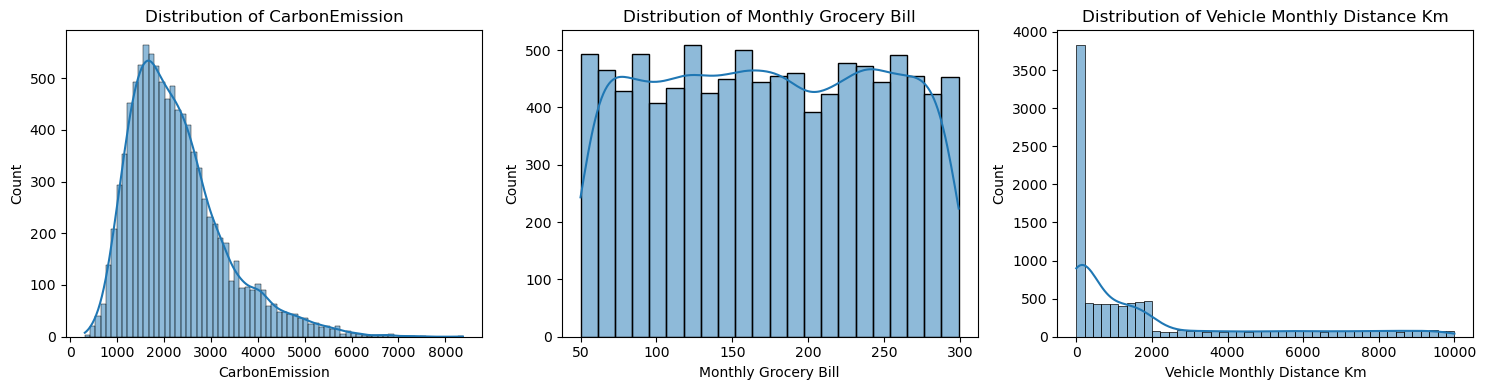

In [15]:
# Plot the target distribution and up to two numeric predictors in one compact figure
plot_cols = [target] + feature_num_cols[:2]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(5 * len(plot_cols), 4))
if len(plot_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, plot_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

#### Categorical feature overview

Separate pie charts for every category are unnecessary and can make the notebook difficult to read. We will use one focused comparison of average carbon emissions by a few meaningful categorical features instead.

In [16]:
# No separate pie charts: category frequencies are available in value_counts() when needed
for col in cat_cols[:3]:
    print(f"\n{col} category counts:")
    display(df[col].value_counts(dropna=False).head(10))


Body Type category counts:


Body Type
underweight    2540
obese          2500
overweight     2487
normal         2473
Name: count, dtype: int64


Sex category counts:


Sex
female    5007
male      4993
Name: count, dtype: int64


Diet category counts:


Diet
pescatarian    2554
vegan          2497
omnivore       2492
vegetarian     2457
Name: count, dtype: int64

#### Numerical outliers

Rather than creating a boxplot for every numeric column, we inspect the target variable's spread here. Outliers are not automatically errors and should not be removed without a reason.

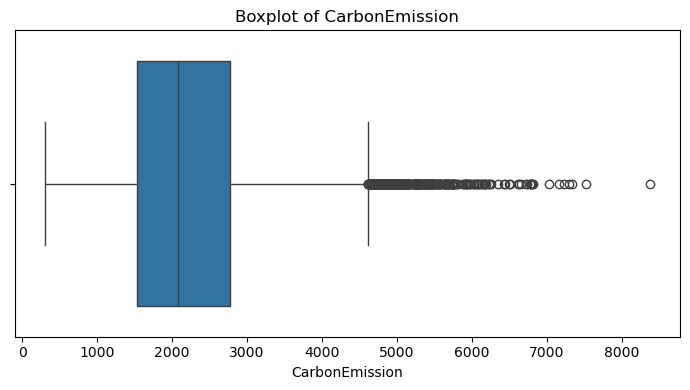

In [17]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=target)
plt.title(f"Boxplot of {target}")
plt.tight_layout()
plt.show()

#### Additional boxplots

We do not need separate boxplots for every feature at this stage. The target boxplot above provides a quick outlier check; use `df[feature_num_cols].describe()` to investigate any predictor that looks unusual.

In [18]:
# Numeric feature summary for checking unusual ranges without generating many plots
df[feature_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Monthly Grocery Bill,10000.0,173.8752,72.234018,50.0,111.0,173.0,237.00,299.0
Vehicle Monthly Distance Km,10000.0,2031.4859,2769.715597,0.0,69.0,823.0,2516.75,9999.0
Waste Bag Weekly Count,10000.0,4.0246,1.990375,1.0,2.0,4.0,6.00,7.0
How Long TV PC Daily Hour,10000.0,12.1392,7.106369,0.0,6.0,12.0,18.00,24.0
How Many New Clothes Monthly,10000.0,25.1090,14.698725,0.0,13.0,25.0,38.00,50.0
How Long Internet Daily Hour,10000.0,11.8891,7.277218,0.0,6.0,12.0,18.00,24.0


### Bivariate analysis: selected categorical features vs target

Compare average carbon emissions across a few relevant categorical variables. This keeps the analysis focused while still showing how groups differ.

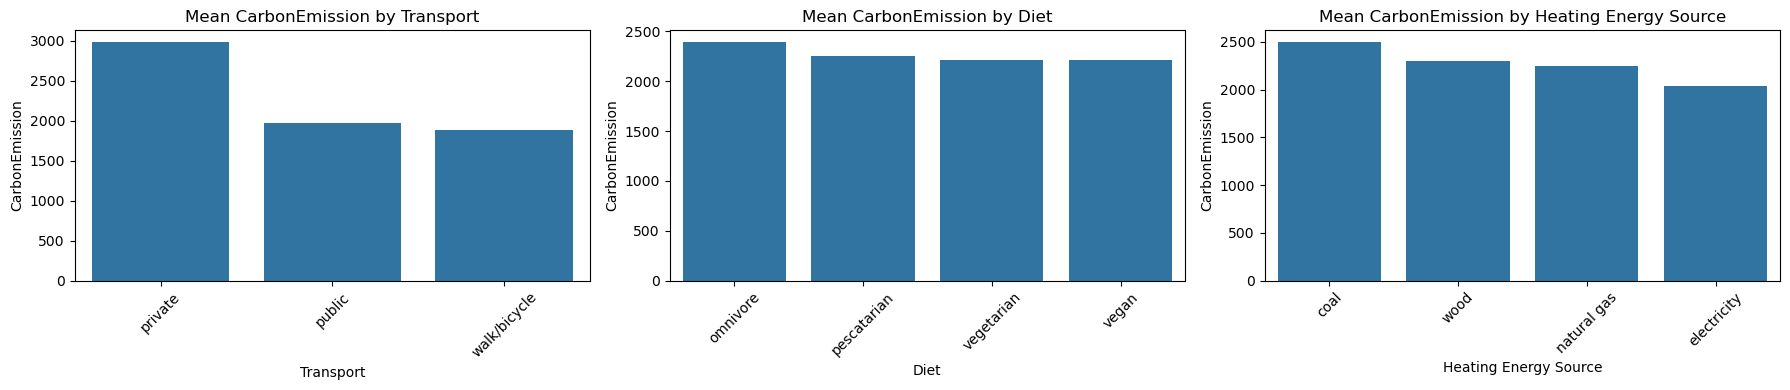

In [19]:
selected_cat_cols = [c for c in ["Transport", "Diet", "Heating Energy Source"] if c in cat_cols]
if selected_cat_cols:
    fig, axes = plt.subplots(1, len(selected_cat_cols), figsize=(6 * len(selected_cat_cols), 4))
    if len(selected_cat_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, selected_cat_cols):
        order = df.groupby(col, dropna=False)[target].mean().sort_values(ascending=False).index
        sns.barplot(data=df, x=col, y=target, order=order, errorbar=None, ax=ax)
        ax.set_title(f"Mean {target} by {col}")
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("The selected categorical columns are not present. Available columns:", cat_cols)

In [20]:
corr = df.select_dtypes(include=np.number).corr()

### Bivariate analysis: numerical predictors vs target

We plot the two numerical predictors most strongly correlated with carbon emissions. These plots help assess whether a linear relationship is plausible.

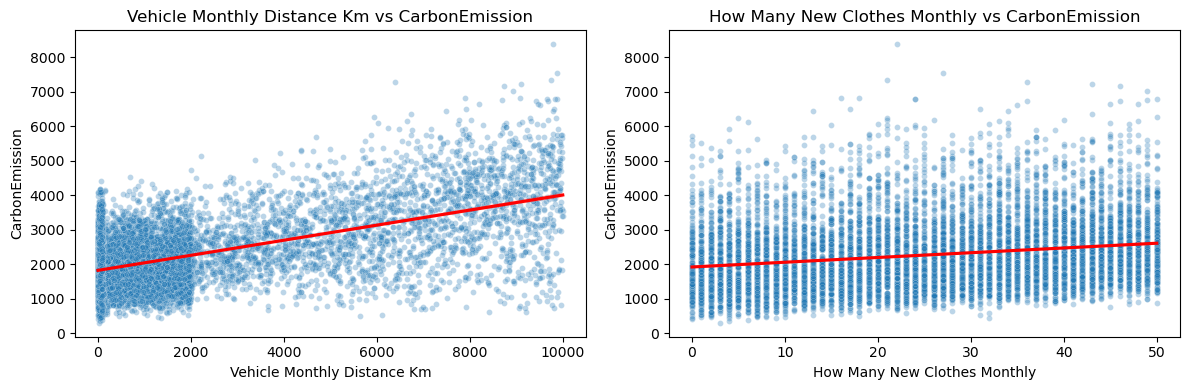

In [21]:
top_scatter_features = corr[target].drop(target).abs().sort_values(ascending=False).head(2).index.tolist()
fig, axes = plt.subplots(1, len(top_scatter_features), figsize=(6 * len(top_scatter_features), 4))
if len(top_scatter_features) == 1:
    axes = [axes]
for ax, col in zip(axes, top_scatter_features):
    sns.scatterplot(data=df, x=col, y=target, alpha=0.3, s=18, ax=ax)
    sns.regplot(data=df, x=col, y=target, scatter=False, ax=ax, color="red")
    ax.set_title(f"{col} vs {target}")
plt.tight_layout()
plt.show()

### Correlation analysis (numerical features)

The correlation matrix summarizes linear associations between numerical variables. We use a compact heatmap without cell-by-cell labels to keep it readable.

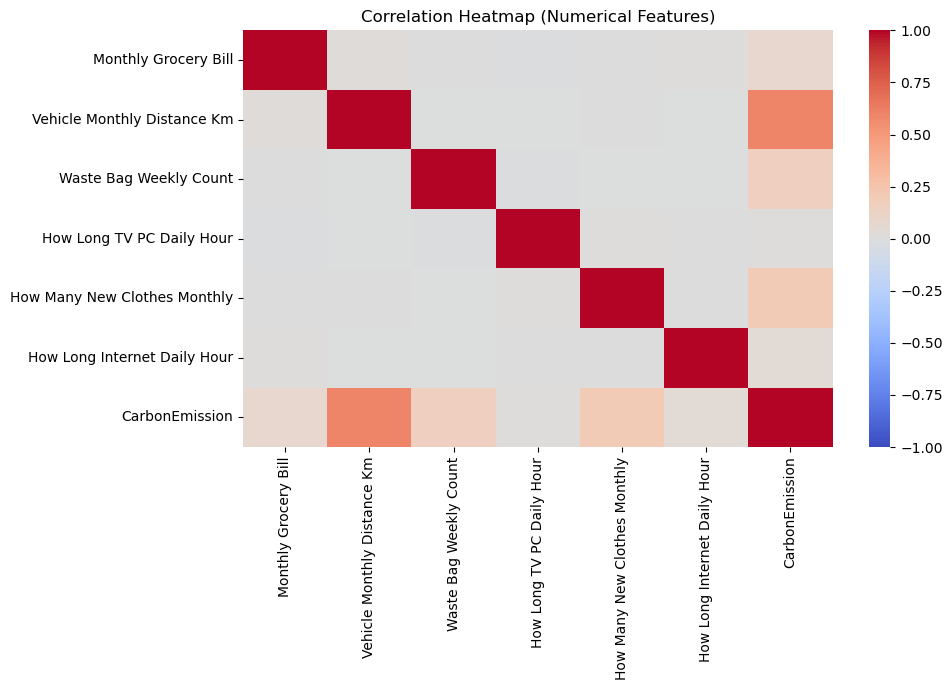

Numerical features most correlated with CarbonEmission:


,Correlation with CarbonEmission
Vehicle Monthly Distance Km,0.594171
How Many New Clothes Monthly,0.198887
Waste Bag Weekly Count,0.159193
Monthly Grocery Bill,0.081587
How Long Internet Daily Hour,0.043878


In [22]:
corr = df[num_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=False, vmin=-1, vmax=1, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numerical Features)")
plt.tight_layout()
plt.show()

print("Numerical features most correlated with CarbonEmission:")
display(corr[target].drop(target).sort_values(key=abs, ascending=False).head(5).to_frame("Correlation with CarbonEmission"))

## Feature Engineering

### Encode categorical variables

Linear Regression requires numeric inputs. We use one-hot encoding to turn categorical columns into indicator variables and drop the first category from each column to reduce redundant dummy columns.

In [23]:
df_model = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print("Original shape:", df.shape)
print("Encoded shape:", df_model.shape)
print(df_model.columns.tolist())

Original shape: (10000, 20)
Encoded shape: (10000, 67)
['Monthly Grocery Bill', 'Vehicle Monthly Distance Km', 'Waste Bag Weekly Count', 'How Long TV PC Daily Hour', 'How Many New Clothes Monthly', 'How Long Internet Daily Hour', 'CarbonEmission', 'Body Type_obese', 'Body Type_overweight', 'Body Type_underweight', 'Sex_male', 'Diet_pescatarian', 'Diet_vegan', 'Diet_vegetarian', 'How Often Shower_less frequently', 'How Often Shower_more frequently', 'How Often Shower_twice a day', 'Heating Energy Source_electricity', 'Heating Energy Source_natural gas', 'Heating Energy Source_wood', 'Transport_public', 'Transport_walk/bicycle', 'Vehicle Type_diesel', 'Vehicle Type_electric', 'Vehicle Type_hybrid', 'Vehicle Type_lpg', 'Vehicle Type_petrol', 'Social Activity_often', 'Social Activity_sometimes', 'Frequency of Traveling by Air_never', 'Frequency of Traveling by Air_rarely', 'Frequency of Traveling by Air_very frequently', 'Waste Bag Size_large', 'Waste Bag Size_medium', 'Waste Bag Size_smal

### Step: Define features (X) and target (y)

`CarbonEmission` is the variable we want to predict. All other columns become input features.

In [24]:
X = df_model.drop(columns=[target])
y = df_model[target].astype(float)

# Ensure all model inputs are numeric.
X = X.astype(float)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 66)
y shape: (10000,)


In [25]:
X.head()

,Monthly Grocery Bill,Vehicle Monthly Distance Km,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Body Type_obese,Body Type_overweight,Body Type_underweight,Sex_male,...,Cooking_With_['Oven'],"Cooking_With_['Stove', 'Grill', 'Airfryer']","Cooking_With_['Stove', 'Microwave', 'Grill', 'Airfryer']","Cooking_With_['Stove', 'Microwave']","Cooking_With_['Stove', 'Oven', 'Grill', 'Airfryer']","Cooking_With_['Stove', 'Oven', 'Microwave', 'Grill', 'Airfryer']","Cooking_With_['Stove', 'Oven', 'Microwave']","Cooking_With_['Stove', 'Oven']",Cooking_With_['Stove'],Cooking_With_[]
0,230.0,210.0,4.0,7.0,26.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,114.0,9.0,3.0,9.0,38.0,5.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,138.0,2472.0,1.0,14.0,47.0,6.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,157.0,74.0,3.0,20.0,5.0,7.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,266.0,8457.0,1.0,3.0,5.0,6.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
y.head()

0    2238.0
1    1892.0
2    2595.0
3    1074.0
4    4743.0
Name: CarbonEmission, dtype: float64

## Baseline statistical model (OLS)

### OLS regression summary

Ordinary Least Squares (OLS) provides coefficient estimates, p-values, R-squared, adjusted R-squared, and other statistical diagnostics. For a large one-hot encoded dataset, this summary may be lengthy.

In [27]:
# Add an intercept and fit OLS on the full encoded dataset for statistical interpretation.
X_ols = sm.add_constant(X, has_constant="add")
ols_model = sm.OLS(y, X_ols).fit()
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         CarbonEmission   R-squared:                       0.934
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     2163.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        01:50:05   Log-Likelihood:                -69850.
No. Observations:               10000   AIC:                         1.398e+05
Df Residuals:                    9934   BIC:                         1.403e+05
Df Model:                          65                                         
Covariance Type:            nonrobust                                         
====================================================================================================================================
                                                                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------
const                                                             1043.4817     20.298     51.409      0.000    1003.694    1083.270
Monthly Grocery Bill                                                 0.9073      0.036     24.899      0.000       0.836       0.979
Vehicle Monthly Distance Km                                          0.2057      0.002    132.255      0.000       0.203       0.209
Waste Bag Weekly Count                                              82.0376      1.322     62.075      0.000      79.447      84.628
How Long TV PC Daily Hour                                            2.7522      0.370      7.440      0.000       2.027       3.477
How Many New Clothes Monthly                                        13.6170      0.179     76.141      0.000      13.266      13.968
How Long Internet Daily Hour                                         7.0672      0.362     19.544      0.000       6.358       7.776
Body Type_obese                                                    419.7219      7.458     56.277      0.000     405.103     434.341
Body Type_overweight                                               205.5295      7.473     27.505      0.000     190.882     220.177
Body Type_underweight                                             -117.2133      7.431    -15.774      0.000    -131.779    -102.647
Sex_male                                                           337.6844      5.263     64.159      0.000     327.367     348.001
Diet_pescatarian                                                   -89.2256      7.416    -12.032      0.000    -103.762     -74.689
Diet_vegan                                                        -159.7996      7.460    -21.422      0.000    -174.422    -145.177
Diet_vegetarian                                                   -134.4843      7.487    -17.963      0.000    -149.160    -119.809
How Often Shower_less frequently                                    -7.2901      7.417     -0.983      0.326     -21.828       7.248
How Often Shower_more frequently                                    31.8001      7.448      4.270      0.000      17.200      46.400
How Often Shower_twice a day                                        22.6348      7.403      3.057      0.002       8.123      37.147
Heating Energy Source_electricity                                 -427.2456      7.380    -57.895      0.000    -441.711    -412.780
Heating Energy Source_natural gas                                 -201.4733      7.454    -27.030      0.000    -216.084    -186.863
Heating Energy Source_wood                                        -196.4241      7.450    -26.367      0.000    -211.027    -181.821
Transport_public        

#### Compare R-squared and adjusted R-squared

In [28]:
print("OLS R-squared:", ols_model.rsquared)
print("OLS adjusted R-squared:", ols_model.rsquared_adj)

OLS R-squared: 0.9340112267507132
OLS adjusted R-squared: 0.9335794499980251


#### Split data into train and test sets

We hold out 30% of the observations for testing. The test set is used only for final evaluation.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=57
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)

X_train: (7000, 66) X_test: (3000, 66)
y_train: (7000,) y_test: (3000,)


## Baseline ML model (Linear Regression)

### Train/test split and scikit-learn model

We fit a Linear Regression model on the training data and evaluate predictions on the held-out test data using MAE, MSE, RMSE, and R-squared.

### Metric helper

- **MAE:** Average absolute prediction error.
- **MSE:** Average squared prediction error.
- **RMSE:** Square root of MSE, expressed in the target's units.
- **R²:** Proportion of target variance explained by the model.

In [30]:
def eval_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return pd.DataFrame({
        "Metric": ["MAE", "MSE", "RMSE", "R2"],
        "Value": [mae, mse, rmse, r2]
    })

### Train the baseline Linear Regression model

In [31]:
lr1 = LinearRegression()
lr1.fit(X_train, y_train)

LinearRegression()

### Make predictions on the test set

In [32]:
y_pred_lr1 = lr1.predict(X_test)
eval_model(y_test, y_pred_lr1)

,Metric,Value
0,MAE,169.386201
1,MSE,65539.508168
2,RMSE,256.006852
3,R2,0.933435


### Quick overfitting check

Compare training and testing R-squared. A large gap can indicate overfitting, while similar scores suggest more consistent generalization.

In [33]:
print("Train R2:", lr1.score(X_train, y_train))
print("Test R2:", lr1.score(X_test, y_test))

Train R2: 0.9339401165962207
Test R2: 0.9334347880683523


### Coefficients and intercept

Each coefficient estimates the change in predicted `CarbonEmission` for a one-unit change in that feature, holding other features fixed. For one-hot columns, it compares a category with its reference category.

In [34]:
print("Intercept:", lr1.intercept_)
coef_df = pd.DataFrame({"Feature": X_train.columns, "Coefficient": lr1.coef_})
coef_df.reindex(coef_df["Coefficient"].abs().sort_values(ascending=False).index).head(20)

Intercept: 1166.8381147496405


,Feature,Coefficient
22,Vehicle Type_electric,-1043.800459
25,Vehicle Type_petrol,842.121698
30,Frequency of Traveling by Air_very frequently,660.078819
28,Frequency of Traveling by Air_never,-642.891589
29,Frequency of Traveling by Air_rarely,-471.702383
6,Body Type_obese,429.837256
16,Heating Energy Source_electricity,-423.719951
33,Waste Bag Size_small,-379.618174
24,Vehicle Type_lpg,349.274213
9,Sex_male,339.095580


#### Compare actual and predicted carbon emissions

In [35]:
result = pd.DataFrame({"Actual": y_test, "Predicted": y_pred_lr1})
result.head(10)

,Actual,Predicted
8404,1652.0,1754.490727
799,2272.0,2389.215241
9703,2016.0,2044.806306
5960,554.0,277.574992
8729,488.0,527.478309
7594,2125.0,2370.243217
2795,1922.0,1928.708314
5549,1888.0,2026.630366
1632,1997.0,1779.616968
3272,1813.0,2081.689918


## Regression assumption checks (Part 1)

Linear Regression assumptions are useful for interpreting the model:
1. **Linearity:** relationships between predictors and the target are approximately linear.
2. **Multicollinearity:** predictors should not be excessively redundant.
3. **Homoscedasticity:** residual variance is roughly constant across fitted values.
4. **Residual normality:** residuals are approximately normally distributed, especially for inference.

These checks are diagnostic guides, not automatic pass/fail rules.

### 1. Linearity check

The focused scatterplots above already show the relationship between the strongest numerical predictors and the target. We reuse those results instead of generating duplicate charts.

In [36]:
top_features = corr[target].drop(target).abs().sort_values(ascending=False).head(3).index.tolist()
print("Top numerical features correlated with target:", top_features)
print("Review the scatterplots in the bivariate analysis section above for the linearity pattern.")

Top numerical features correlated with target: ['Vehicle Monthly Distance Km', 'How Many New Clothes Monthly', 'Waste Bag Weekly Count']
Review the scatterplots in the bivariate analysis section above for the linearity pattern.


**Observation guide:** Look for an approximately straight trend. A curved pattern suggests that a straight-line model may miss structure.

### 2. Multicollinearity check (VIF)

Variance Inflation Factor (VIF) estimates how much a predictor's coefficient variance is inflated by linear relationships with other predictors. To keep this check interpretable, we calculate VIF on the original numerical predictor columns.

In [37]:
vif_features = [c for c in feature_num_cols if df[c].nunique() > 1]
if len(vif_features) >= 2:
    X_vif = df[vif_features].astype(float).copy()
    X_vif_const = sm.add_constant(X_vif, has_constant="add")
    vif_df = pd.DataFrame({
        "Feature": X_vif.columns,
        "VIF": [
            variance_inflation_factor(X_vif_const.values, i + 1)
            for i in range(len(X_vif.columns))
        ]
    }).sort_values("VIF", ascending=False)
    display(vif_df)
else:
    print("Not enough varying numerical predictors to calculate VIF.")

,Feature,VIF
0,Monthly Grocery Bill,1.000572
3,How Long TV PC Daily Hour,1.000392
1,Vehicle Monthly Distance Km,1.000305
5,How Long Internet Daily Hour,1.000293
4,How Many New Clothes Monthly,1.000208
2,Waste Bag Weekly Count,1.000181


**Observation guide:** VIF values around 1 to 5 are often acceptable; values above 10 can indicate a strong multicollinearity concern. These are rules of thumb, not strict laws.

### 3. Homoscedasticity check (residuals vs predicted)

Residuals are actual values minus predictions. Ideally, they are scattered around zero without a funnel-shaped pattern.

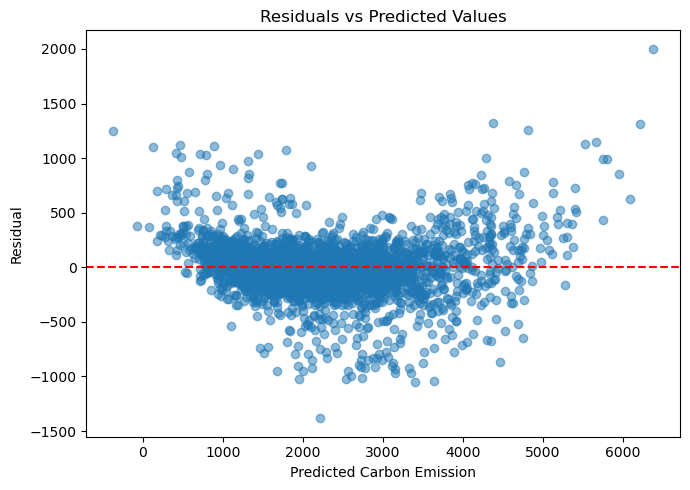

In [38]:
residuals = y_test - y_pred_lr1

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_lr1, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Carbon Emission")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

#### Breusch–Pagan and Durbin–Watson diagnostics

The Breusch–Pagan test checks for evidence of non-constant residual variance. Durbin–Watson is a check for residual autocorrelation, although this dataset is not necessarily time ordered.

In [39]:
X_train_sm = sm.add_constant(X_train, has_constant="add")
ols_train = sm.OLS(y_train, X_train_sm).fit()
bp_test = het_breuschpagan(ols_train.resid, ols_train.model.exog)
print("Breusch-Pagan LM statistic:", bp_test[0])
print("Breusch-Pagan p-value:", bp_test[1])
print("Durbin-Watson:", durbin_watson(ols_train.resid))

Breusch-Pagan LM statistic: 2528.4546829964356
Breusch-Pagan p-value: 0.0
Durbin-Watson: 1.9731154530090778


**Observation guide:** A Breusch–Pagan p-value below 0.05 suggests evidence of heteroscedasticity. Durbin–Watson near 2 suggests little residual autocorrelation, but interpretation depends on the data structure.

### 4. Normality of residuals

We use one combined figure with a residual histogram and Q-Q plot. This is sufficient for a visual check without creating extra charts.

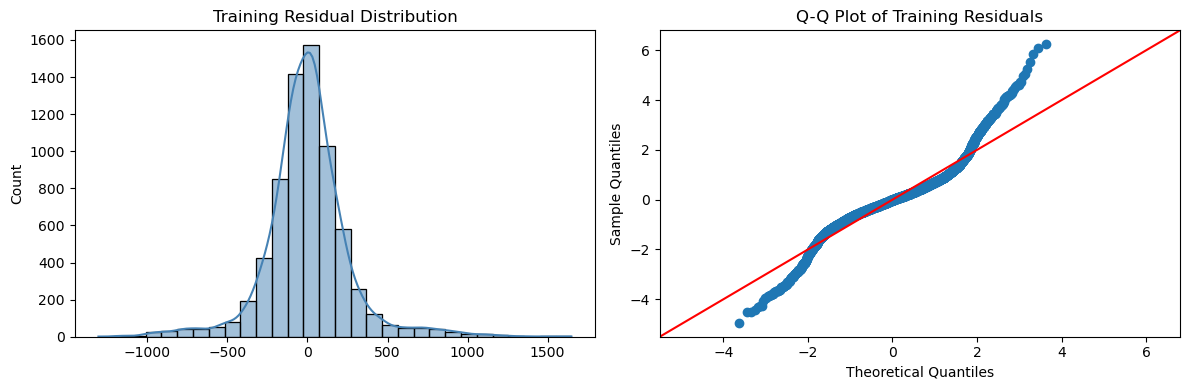

In [40]:
residuals_train = ols_train.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residuals_train, bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Training Residual Distribution")
sm.qqplot(residuals_train, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q Plot of Training Residuals")
plt.tight_layout()
plt.show()

---

# Part 2 – Regularized Regression

In Part 2, we use the same encoded dataset and train/test split to compare **Ridge**, **Lasso**, and **ElasticNet** with the baseline Linear Regression model.

Regularization penalizes large coefficients and can improve model stability when predictors are correlated.

## Step 1: Why scaling is used here

Ridge, Lasso, and ElasticNet are sensitive to feature scales. We standardize features using statistics learned only from the training set, then apply the same transformation to the test set.

In [41]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (7000, 66)
Scaled test shape: (3000, 66)


## Step 2: Train Ridge, Lasso, and ElasticNet (no cross-validation yet)

We first train each regularized model with a reasonable starting configuration. This gives an initial comparison against the baseline.

In [42]:
def get_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results_initial = []

### Baseline model from Part 1

In [43]:
pred_baseline = lr1.predict(X_test)
baseline_metrics = get_metrics(y_test, pred_baseline)
baseline_metrics["Model"] = "Baseline Linear Regression"
results_initial.append(baseline_metrics)
baseline_metrics

{'MAE': 169.38620079137007,
 'RMSE': np.float64(256.00685179832493),
 'R2': 0.9334347880683523,
 'Model': 'Baseline Linear Regression'}

### Ridge (L2 regularization)

In [44]:
ridge_basic = Ridge(alpha=1.0)
ridge_basic.fit(X_train_scaled, y_train)
pred_ridge = ridge_basic.predict(X_test_scaled)
m_ridge = get_metrics(y_test, pred_ridge)
m_ridge["Model"] = "Ridge (alpha=1.0)"
results_initial.append(m_ridge)
m_ridge

{'MAE': 169.37978468534016,
 'RMSE': np.float64(256.00131690964315),
 'R2': 0.9334376663276862,
 'Model': 'Ridge (alpha=1.0)'}

### Lasso (L1 regularization)

In [45]:
lasso_basic = Lasso(alpha=0.01, max_iter=5000)
lasso_basic.fit(X_train_scaled, y_train)
pred_lasso = lasso_basic.predict(X_test_scaled)
m_lasso = get_metrics(y_test, pred_lasso)
m_lasso["Model"] = "Lasso (alpha=0.01)"
results_initial.append(m_lasso)
m_lasso

{'MAE': 169.3835539047254,
 'RMSE': np.float64(256.00395698620275),
 'R2': 0.9334362934397251,
 'Model': 'Lasso (alpha=0.01)'}

### ElasticNet (L1 + L2 regularization)

In [46]:
enet_basic = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000)
enet_basic.fit(X_train_scaled, y_train)
pred_enet = enet_basic.predict(X_test_scaled)
m_enet = get_metrics(y_test, pred_enet)
m_enet["Model"] = "ElasticNet (alpha=0.01, l1_ratio=0.5)"
results_initial.append(m_enet)
m_enet

{'MAE': 169.21306498150315,
 'RMSE': np.float64(255.88658353719305),
 'R2': 0.9334973160964786,
 'Model': 'ElasticNet (alpha=0.01, l1_ratio=0.5)'}

In [47]:
results_initial_df = pd.DataFrame(results_initial).sort_values("RMSE")
results_initial_df

,MAE,RMSE,R2,Model
3,169.213065,255.886584,0.933497,"ElasticNet (alpha=0.01, l1_ratio=0.5)"
1,169.379785,256.001317,0.933438,Ridge (alpha=1.0)
2,169.383554,256.003957,0.933436,Lasso (alpha=0.01)
0,169.386201,256.006852,0.933435,Baseline Linear Regression


**Observation:** Lower MAE and RMSE indicate smaller prediction errors; higher R² indicates more target variation explained. Compare all metrics rather than relying on one score alone.

## Step 3: K-Fold cross-validation

A single train/test split provides one estimate of performance. K-Fold cross-validation divides the training data into five folds, training on four folds and validating on the remaining fold each time.

In [48]:
def kfold_score(model_class, model_params, X, y, k=5, random_state=57):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    model = model_class(**model_params)
    cv_results = cross_validate(
        model,
        X,
        y,
        cv=kf,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )
    rmse_scores = -cv_results["test_rmse"]
    r2_scores = cv_results["test_r2"]
    return {
        "RMSE_Mean": rmse_scores.mean(),
        "RMSE_Std": rmse_scores.std(),
        "R2_Mean": r2_scores.mean()
    }

## Step 4: Tune Ridge (alpha) with K-Fold

The Ridge `alpha` parameter controls the strength of the penalty. We choose the value with the lowest mean cross-validation RMSE.

In [49]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000]
ridge_cv_results = []
for alpha in ridge_alphas:
    res = kfold_score(Ridge, {"alpha": alpha}, X_train_scaled, y_train)
    res["Model"] = "Ridge"
    res["alpha"] = alpha
    ridge_cv_results.append(res)

ridge_cv_df = pd.DataFrame(ridge_cv_results).sort_values("RMSE_Mean")
ridge_cv_df

,RMSE_Mean,RMSE_Std,R2_Mean,Model,alpha
2,267.129062,5.702688,0.932419,Ridge,1.00
3,267.129127,5.749393,0.932419,Ridge,10.00
1,267.129928,5.698024,0.932418,Ridge,0.10
0,267.130023,5.697557,0.932418,Ridge,0.01
4,267.913328,6.217001,0.932024,Ridge,100.00
5,309.405456,9.685752,0.909351,Ridge,1000.00


## Step 5: Tune Lasso (alpha) with K-Fold

Lasso can shrink some coefficients exactly to zero, which can act as feature selection. We compare multiple alpha values.

In [50]:
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]
lasso_cv_results = []
for alpha in lasso_alphas:
    res = kfold_score(Lasso, {"alpha": alpha, "max_iter": 5000}, X_train_scaled, y_train)
    res["Model"] = "Lasso"
    res["alpha"] = alpha
    lasso_cv_results.append(res)

lasso_cv_df = pd.DataFrame(lasso_cv_results).sort_values("RMSE_Mean")
lasso_cv_df

,RMSE_Mean,RMSE_Std,R2_Mean,Model,alpha
3,267.113558,5.672371,0.932427,Lasso,0.1000
2,267.128121,5.694975,0.932419,Lasso,0.0100
1,267.129826,5.697260,0.932418,Lasso,0.0010
0,267.130013,5.697481,0.932418,Lasso,0.0001
4,267.189867,5.550223,0.932387,Lasso,1.0000


## Step 6: Tune ElasticNet (alpha and l1_ratio) with K-Fold

ElasticNet combines Ridge and Lasso penalties. `alpha` controls overall penalty strength, while `l1_ratio` controls the mix between L1 and L2 penalties.

In [51]:
enet_alphas = [0.001, 0.01, 0.1, 1, 10]
enet_l1_ratios = [0.1, 0.5, 0.9]
enet_cv_results = []

for alpha in enet_alphas:
    for l1_ratio in enet_l1_ratios:
        res = kfold_score(
            ElasticNet,
            {"alpha": alpha, "l1_ratio": l1_ratio, "max_iter": 5000},
            X_train_scaled, y_train
        )
        res["Model"] = "ElasticNet"
        res["alpha"] = alpha
        res["l1_ratio"] = l1_ratio
        enet_cv_results.append(res)

enet_cv_df = pd.DataFrame(enet_cv_results).sort_values("RMSE_Mean")
enet_cv_df

,RMSE_Mean,RMSE_Std,R2_Mean,Model,alpha,l1_ratio
5,267.125598,5.724333,0.932421,ElasticNet,0.010,0.9
0,267.127123,5.723615,0.932420,ElasticNet,0.001,0.1
1,267.127714,5.711895,0.932420,ElasticNet,0.001,0.5
2,267.129281,5.700158,0.932419,ElasticNet,0.001,0.9
4,267.175109,5.841912,0.932396,ElasticNet,0.010,0.5
3,267.314374,5.959510,0.932326,ElasticNet,0.010,0.1
8,267.375888,5.971131,0.932295,ElasticNet,0.100,0.9
7,272.736916,7.099900,0.929558,ElasticNet,0.100,0.5
6,282.287587,8.070513,0.924541,ElasticNet,0.100,0.1
11,286.434790,8.216700,0.922308,ElasticNet,1.000,0.9


## Step 7: Compare the best configuration from each model

We select the lowest-RMSE cross-validation configuration for each regularized model.

In [52]:
best_ridge = ridge_cv_df.iloc[0]
best_lasso = lasso_cv_df.iloc[0]
best_enet = enet_cv_df.iloc[0]

compare_cv = pd.DataFrame([best_ridge, best_lasso, best_enet])
compare_cv[["Model", "RMSE_Mean", "RMSE_Std", "R2_Mean", "alpha"] + (["l1_ratio"] if "l1_ratio" in compare_cv.columns else [])]

,Model,RMSE_Mean,RMSE_Std,R2_Mean,alpha,l1_ratio
2,Ridge,267.129062,5.702688,0.932419,1.00,NaN
3,Lasso,267.113558,5.672371,0.932427,0.10,NaN
5,ElasticNet,267.125598,5.724333,0.932421,0.01,0.9


Now train the tuned Ridge, Lasso, and ElasticNet models on the full training data and evaluate them on the held-out test set.

In [53]:
results_list = []
results_list.append({
    "Model": "Baseline Linear Regression",
    **get_metrics(y_test, lr1.predict(X_test))
})

ridge_best_params = {"alpha": float(best_ridge["alpha"])}
ridge_tuned = Ridge(**ridge_best_params).fit(X_train_scaled, y_train)
results_list.append({
    "Model": f"Ridge (alpha={ridge_best_params['alpha']})",
    **get_metrics(y_test, ridge_tuned.predict(X_test_scaled))
})

lasso_best_params = {"alpha": float(best_lasso["alpha"]), "max_iter": 5000}
lasso_tuned = Lasso(**lasso_best_params).fit(X_train_scaled, y_train)
results_list.append({
    "Model": f"Lasso (alpha={lasso_best_params['alpha']})",
    **get_metrics(y_test, lasso_tuned.predict(X_test_scaled))
})

enet_best_params = {
    "alpha": float(best_enet["alpha"]),
    "l1_ratio": float(best_enet["l1_ratio"]),
    "max_iter": 5000
}
enet_tuned = ElasticNet(**enet_best_params).fit(X_train_scaled, y_train)
results_list.append({
    "Model": f"ElasticNet (alpha={enet_best_params['alpha']}, l1_ratio={enet_best_params['l1_ratio']})",
    **get_metrics(y_test, enet_tuned.predict(X_test_scaled))
})

final_comparison = pd.DataFrame(results_list).sort_values("RMSE")
final_comparison

,Model,MAE,RMSE,R2
3,"ElasticNet (alpha=0.01, l1_ratio=0.9)",169.341081,255.968362,0.933455
2,Lasso (alpha=0.1),169.360383,255.978290,0.933450
1,Ridge (alpha=1.0),169.379785,256.001317,0.933438
0,Baseline Linear Regression,169.386201,256.006852,0.933435


**Observation:** Prefer lower test RMSE and MAE, higher test R², and stable cross-validation scores. A tiny metric difference should not be over-interpreted.

## Step 8: Coefficient inspection (shrinkage vs feature removal)

Compare coefficients from a Linear Regression model on scaled features with the tuned regularized models. Ridge generally shrinks coefficients, while Lasso may set some to zero.

In [54]:
lr_scaled = LinearRegression().fit(X_train_scaled, y_train)

coef_comparison = pd.DataFrame({
    "Feature": X_train.columns,
    "LinearRegression": lr_scaled.coef_,
    "Ridge": ridge_tuned.coef_,
    "Lasso": lasso_tuned.coef_,
    "ElasticNet": enet_tuned.coef_
})
coef_comparison["Lasso_Zero"] = np.isclose(coef_comparison["Lasso"], 0)
coef_comparison.reindex(
    coef_comparison["LinearRegression"].abs().sort_values(ascending=False).index
).head(25)

,Feature,LinearRegression,Ridge,Lasso,ElasticNet,Lasso_Zero
1,Vehicle Monthly Distance Km,575.501140,575.291341,575.397722,574.017627,False
30,Frequency of Traveling by Air_very frequently,286.634496,286.622500,286.625587,286.549541,False
28,Frequency of Traveling by Air_never,-276.499444,-276.450683,-276.346986,-276.145031,False
22,Vehicle Type_electric,-253.964761,-253.879603,-259.160161,-254.409144,False
25,Vehicle Type_petrol,216.074749,216.094351,210.717277,215.162383,False
29,Frequency of Traveling by Air_rarely,-203.980058,-203.934841,-203.833564,-203.650846,False
4,How Many New Clothes Monthly,200.284914,200.255652,200.196431,200.072235,False
6,Body Type_obese,186.758773,186.714404,186.591891,186.434041,False
16,Heating Energy Source_electricity,-183.754853,-183.697068,-183.464606,-183.325155,False
9,Sex_male,169.537797,169.512159,169.429611,169.348654,False


## Step 9: Select ONE final model and justify

We select the best regularized model based on cross-validation RMSE, then inspect its held-out test metrics. The baseline Linear Regression remains in the comparison as a reference.

In [55]:
best_candidates = {
    "Ridge": float(best_ridge["RMSE_Mean"]),
    "Lasso": float(best_lasso["RMSE_Mean"]),
    "ElasticNet": float(best_enet["RMSE_Mean"])
}
winner = min(best_candidates, key=best_candidates.get)

winner_row = final_comparison[final_comparison["Model"].str.startswith(winner)].iloc[0]
print("Selected regularized model:", winner)
print("Lowest CV mean RMSE:", best_candidates[winner])
print("Test metrics:")
display(winner_row.to_frame("Value"))

print(
    "Justification: The selected model has the lowest mean RMSE among the tuned "
    "regularized models under 5-fold cross-validation. Its test-set MAE, RMSE, and "
    "R-squared should also be compared with the baseline before making a final conclusion."
)

Selected regularized model: Lasso
Lowest CV mean RMSE: 267.113557990107
Test metrics:


,Value
Model,Lasso (alpha=0.1)
MAE,169.360383
RMSE,255.97829
R2,0.93345


Justification: The selected model has the lowest mean RMSE among the tuned regularized models under 5-fold cross-validation. Its test-set MAE, RMSE, and R-squared should also be compared with the baseline before making a final conclusion.


## Conclusion

This project demonstrates how Linear Regression and regularization techniques can predict carbon emissions using lifestyle, transportation, and energy consumption data. Comparing model performance helps identify a suitable predictive model. The results highlight the potential of data analytics in understanding emission patterns and promoting sustainable choices.